<a href="https://colab.research.google.com/github/miriammixon2/aerial-disaster-triage/blob/main/demo_day_notebook_(clean%2C_100_images_hf).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q transformers huggingface_hub 2>/dev/null

import os, random, posixpath, warnings, logging, time
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)

import numpy as np, torch
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter
from transformers import CLIPModel, CLIPProcessor
from huggingface_hub import list_repo_files, hf_hub_download

REPO = "ckyrkou/AIDERv2"
HOW_MANY = {"Fire": 15, "Flood": 25, "Earthquake": 25, "Normal": 35}

IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
WANTED = {"earthquake": "Earthquake", "flood": "Flood",
          "fire": "Fire", "wildfire": "Fire", "normal": "Normal"}

print("finding photos...")
by_class = {}
for f in list_repo_files(REPO, repo_type="dataset"):
    if not f.lower().endswith(IMG_EXT):
        continue
    parts = [p.lower() for p in posixpath.dirname(f).split("/")]
    hit = next((WANTED[p] for p in parts if p in WANTED), None)
    if hit:
        by_class.setdefault(hit, []).append(f)

if not by_class:
    raise SystemExit("Could not find the photos. Check your internet connection.")

def spread_pick(pool, n, seed=0):
    pool = sorted(pool)
    if n >= len(pool):
        return pool
    rng = random.Random(seed)
    step = len(pool) / n
    return [pool[min(len(pool) - 1, int(i * step + rng.random() * step))]
            for i in range(n)]

picks = [(cls, f) for cls in sorted(by_class)
         for f in spread_pick(by_class[cls], HOW_MANY.get(cls, 0))]

print(f"downloading {len(picks)} photos...")
photos = []
for n, (cls, f) in enumerate(picks, 1):
    photos.append({"path": hf_hub_download(REPO, filename=f, repo_type="dataset",
                                           local_dir="/content/demo_photos"),
                   "true_class": cls})
    if n % 25 == 0:
        print(f"   {n}/{len(picks)}")

print("loading the model...")
model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")
processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
model.eval()

images = [Image.open(r["path"]).convert("RGB") for r in photos]

print(f"\nREADY — {len(photos)} photos loaded")
print(dict(Counter(p["true_class"] for p in photos)))

finding photos...


downloading 100 photos...


test/Earthquake/image_171.png: reconstructing file:   0%|          |  0.00B /  102kB            

test/Earthquake/image_171.png: downloading bytes:           |  0.00B            

test/Earthquake/image_36.png: reconstructing file:   0%|          |  0.00B / 96.2kB            

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]


READY — 100 photos loaded
{'Earthquake': 25, 'Fire': 15, 'Flood': 25, 'Normal': 35}


In [ ]:
TIER_OF = {
    "an aerial photo of a building with colored flames or active smoke":   "IMMEDIATE",
    "an aerial photo of a wildfire burning through trees":                 "IMMEDIATE",
    "an aerial photo of people stranded on a rooftop":                     "IMMEDIATE",
    "an aerial photo of a flooded home":                                   "IMMEDIATE",
    "an aerial photo of a flooded street with water covering cars":        "IMMEDIATE",

    "an aerial photo of a collapsed building":                             "DESTRUCTION",
    "an aerial photo of a crushed car":                                    "DESTRUCTION",
    "an aerial photo of burned scorched area after a fire":                "DESTRUCTION",
    "an aerial photo of a cracked pavement sidewalk":                      "DESTRUCTION",
    "an aerial photo of a burned out building shell with no active fire or smoke": "DESTRUCTION",
    "an aerial photo of rubble and debris from destroyed buildings":       "DESTRUCTION",
    "an aerial photo of scattered storm debris and fallen trees across a road": "DESTRUCTION",
    "an aerial photo of a damaged roof covered with a blue tarp":          "DESTRUCTION",
    "an aerial photo of a cleared lot with piles of sorted rubble":        "DESTRUCTION",

    "an aerial photo of a normal neighborhood with undamaged buildings":   "NORMAL",
    "an aerial photo of a lake":                                           "NORMAL",
    "an aerial photo of a sunset":                                         "NORMAL",
    "an aerial photo of a swimming pool":                                  "NORMAL",
    "an aerial photo of a parking lot":                                    "NORMAL",
    "an aerial photo of a street":                                         "NORMAL",
    "an aerial photo of people in a crowd or in an open space":            "NORMAL",
    "an aerial photo of green tree foliage and forest canopy":             "NORMAL",
    "an aerial photo of a house in deep shadow under trees":               "NORMAL",
    "an aerial photo of farmland or open countryside":                     "NORMAL",
}

ESCALATE_AT = 0.70      # how sure before something is called urgent

for tier in ("IMMEDIATE", "DESTRUCTION", "NORMAL"):
    group = [l for l, t in TIER_OF.items() if t == tier]
    print(f"\n{tier}  ({len(group)} descriptions)")
    print("-" * 68)
    for l in group:
        print("   ", l.replace("an aerial photo of ", ""))

print(f"\n\n{len(TIER_OF)} sentences. That's the whole classifier.")


IMMEDIATE  (5 descriptions)
--------------------------------------------------------------------
    a building with colored flames or active smoke
    a wildfire burning through trees
    people stranded on a rooftop
    a flooded home
    a flooded street with water covering cars

DESTRUCTION  (9 descriptions)
--------------------------------------------------------------------
    a collapsed building
    a crushed car
    burned scorched area after a fire
    a cracked pavement sidewalk
    a burned out building shell with no active fire or smoke
    rubble and debris from destroyed buildings
    scattered storm debris and fallen trees across a road
    a damaged roof covered with a blue tarp
    a cleared lot with piles of sorted rubble

NORMAL  (10 descriptions)
--------------------------------------------------------------------
    a normal neighborhood with undamaged buildings
    a lake
    a sunset
    a swimming pool
    a parking lot
    a street
    people in a crowd or 

In [ ]:
TIERS = ["IMMEDIATE", "DESTRUCTION", "NORMAL"]
LABELS = list(TIER_OF.keys())
EXPECTED_TIER = {"Fire": "IMMEDIATE", "Flood": "IMMEDIATE",
                 "Earthquake": "DESTRUCTION", "Normal": "NORMAL"}
ACTION = {"IMMEDIATE": "dispatch now", "DESTRUCTION": "assess when clear",
          "NORMAL": "no action"}

start = time.time()
chunks = []
for i in range(0, len(images), 16):
    inputs = processor(text=LABELS, images=images[i:i + 16],
                       return_tensors="pt", padding=True)
    with torch.no_grad():
        chunks.append(model(**inputs).logits_per_image.softmax(dim=1).numpy())
scores = np.vstack(chunks)
elapsed = time.time() - start

results = []
for i, rec in enumerate(photos):
    t = {tier: 0.0 for tier in TIERS}
    for label, s in zip(LABELS, scores[i]):
        t[TIER_OF[label]] += float(s)
    verdict = ("IMMEDIATE" if t["IMMEDIATE"] >= ESCALATE_AT
               else max((x for x in TIERS if x != "IMMEDIATE"), key=lambda x: t[x]))
    results.append({**rec, "img": images[i], "tiers": t, "verdict": verdict,
                    "expected": EXPECTED_TIER[rec["true_class"]],
                    "conf": t[verdict],
                    "top": LABELS[int(np.argmax(scores[i]))]
                             .replace("an aerial photo of ", "")})

print(f"{len(photos)} photos triaged in {elapsed:.1f} seconds\n")

rank = {"IMMEDIATE": 1, "DESTRUCTION": 2, "NORMAL": 3}
rows = sorted(results, key=lambda r: (rank[r["verdict"]], -r["conf"]))

print("=" * 76)
print("  DISPATCH LIST")
print("=" * 76)
n = 0
for tier in TIERS:
    group = [r for r in rows if r["verdict"] == tier]
    if not group:
        continue
    print(f"\n  PRIORITY {rank[tier]} — {tier}   ({len(group)} locations)   "
          f"[{ACTION[tier]}]")
    print("  " + "-" * 72)
    for r in group[:10]:
        print(f"  {n+1:3}.  {os.path.basename(r['path'])[:30]:32} "
              f"{r['conf']:5.0%}   {r['top'][:28]}")
        n += 1
    if len(group) > 10:
        print(f"        ... and {len(group) - 10} more")
        n += len(group) - 10

100 photos triaged in 39.4 seconds

  DISPATCH LIST

  PRIORITY 1 — IMMEDIATE   (28 locations)   [dispatch now]
  ------------------------------------------------------------------------
    1.  image_12926.png                   100%   a wildfire burning through t
    2.  image_11698.png                   100%   a wildfire burning through t
    3.  image_5543.png                     99%   people stranded on a rooftop
    4.  image_11143.png                    98%   a wildfire burning through t
    5.  image_2906.png                     98%   a flooded home
    6.  image_1464.png                     98%   a wildfire burning through t
    7.  image_2085.png                     96%   a flooded home
    8.  image_636.png                      96%   a flooded street with water 
    9.  image_10077.png                    96%   a wildfire burning through t
   10.  image_3368.png                     95%   a flooded street with water 
        ... and 18 more

  PRIORITY 2 — DESTRUCTION   (37 loc

ACCURACY   74/100  (74%)

category        correct   usual mistake
------------------------------------------------------
Earthquake      23/25     NORMAL
Fire            11/15     DESTRUCTION
Flood           15/25     NORMAL
Normal          25/35     DESTRUCTION

Not every mistake costs the same:
   10  missed a real emergency      <- the dangerous one
    6  right that it's bad, wrong tier
   10  false alarm                  <- a wasted drive


FLAGGING THE CLOSE CALLS FOR A HUMAN
------------------------------------------------------
  decided on its own    94   76% correct
  sent to a person       6   50% would have been right

  caught 3/26 of all mistakes by reviewing 6% of the photos
  (1.9x better than picking photos at random)




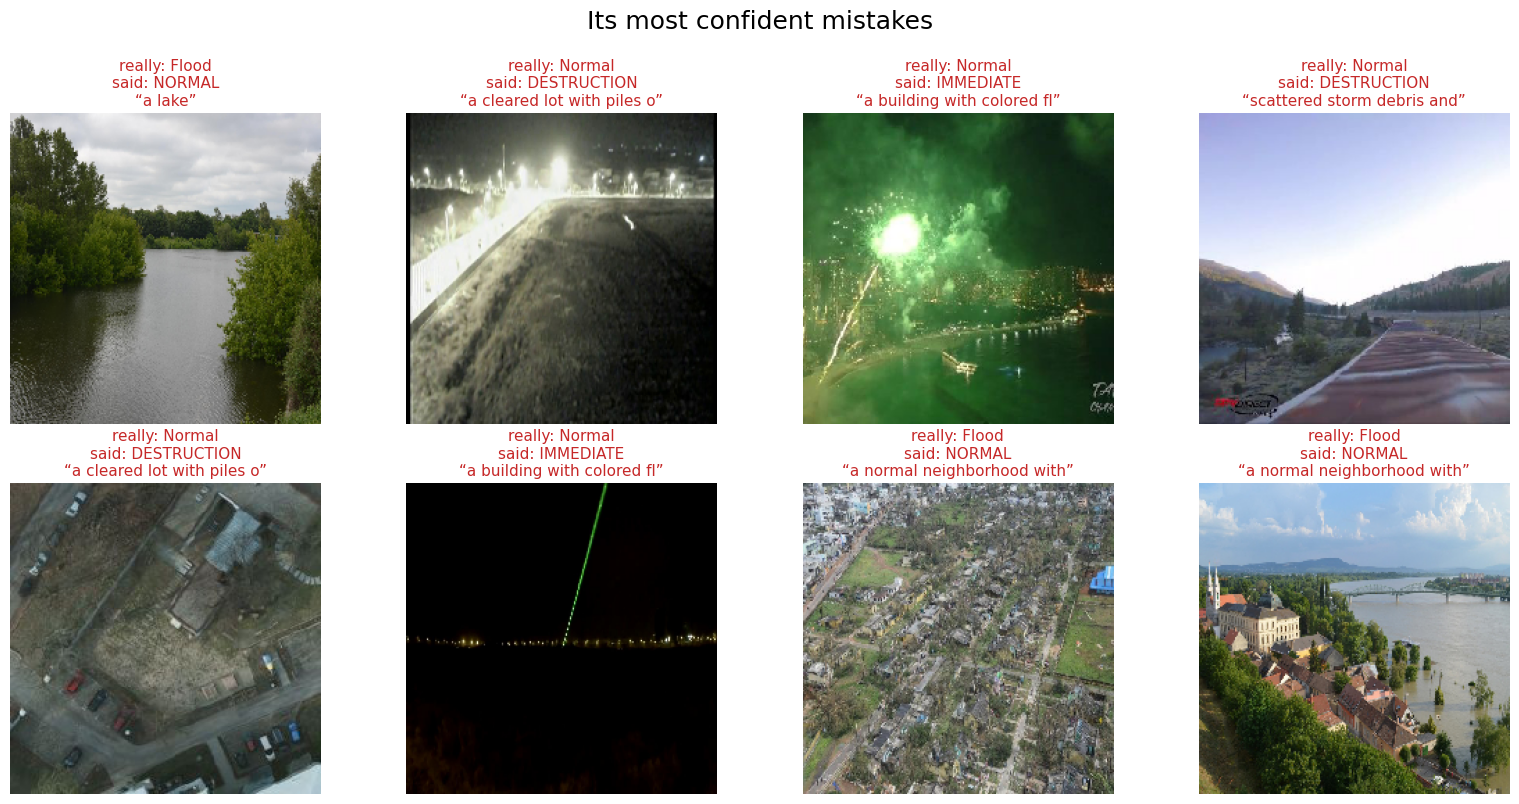

In [ ]:
agree = sum(r["verdict"] == r["expected"] for r in results)
print(f"ACCURACY   {agree}/{len(results)}  ({agree/len(results):.0%})\n")

print(f"{'category':12} {'correct':>10}   usual mistake")
print("-" * 54)
for cls in sorted({r["true_class"] for r in results}):
    grp = [r for r in results if r["true_class"] == cls]
    ok = sum(r["verdict"] == r["expected"] for r in grp)
    wrong = [r["verdict"] for r in grp if r["verdict"] != r["expected"]]
    print(f"{cls:12} {ok:5}/{len(grp):<4}   "
          f"{max(set(wrong), key=wrong.count) if wrong else '-'}")

missed = sum(1 for r in results
             if r["expected"] != "NORMAL" and r["verdict"] == "NORMAL")
false_alarm = sum(1 for r in results
                  if r["expected"] == "NORMAL" and r["verdict"] != "NORMAL")
wrong_tier = sum(1 for r in results
                 if r["verdict"] != r["expected"]
                 and r["expected"] != "NORMAL" and r["verdict"] != "NORMAL")

print(f"\nNot every mistake costs the same:")
print(f"  {missed:3}  missed a real emergency      <- the dangerous one")
print(f"  {wrong_tier:3}  right that it's bad, wrong tier")
print(f"  {false_alarm:3}  false alarm                  <- a wasted drive")

for r in results:
    vals = sorted(r["tiers"].values(), reverse=True)
    r["margin"] = vals[0] - vals[1]
    r["correct"] = r["verdict"] == r["expected"]

MARGIN = 0.10
review = [r for r in results if r["margin"] < MARGIN]
auto   = [r for r in results if r["margin"] >= MARGIN]
errors = [r for r in results if not r["correct"]]

print(f"\n\nFLAGGING THE CLOSE CALLS FOR A HUMAN")
print("-" * 54)
if auto:
    print(f"  decided on its own   {len(auto):3}   "
          f"{sum(r['correct'] for r in auto)/len(auto):.0%} correct")
if review:
    print(f"  sent to a person     {len(review):3}   "
          f"{sum(r['correct'] for r in review)/len(review):.0%} would have been right")
if errors and review:
    caught = sum(r["margin"] < MARGIN for r in errors)
    lift = (caught / len(errors)) / (len(review) / len(results))
    print(f"\n  caught {caught}/{len(errors)} of all mistakes "
          f"by reviewing {len(review)/len(results):.0%} of the photos")
    print(f"  ({lift:.1f}x better than picking photos at random)")

bad = sorted([r for r in results if not r["correct"]],
             key=lambda r: -r["conf"])[:8]
if bad:
    print("\n")
    fig, ax = plt.subplots(2, 4, figsize=(16, 8))
    for k in range(8):
        a = ax[k // 4, k % 4]
        if k < len(bad):
            r = bad[k]
            a.imshow(r["img"])
            a.set_title(f"really: {r['true_class']}\nsaid: {r['verdict']}\n"
                        f"“{r['top'][:26]}”", fontsize=11, color="#c62828")
        a.axis("off")
    fig.suptitle("Its most confident mistakes", fontsize=18, y=1.0)
    plt.tight_layout(); plt.show()